In [1]:
import pandas as pd

# NASA verisini okuma (sep parametresinin başına 'r' ekledik)
df_train = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None)

df_train.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [2]:
# Sütun isimlerini sırasıyla tanımlıyoruz (Motor, Zaman, 3 Ayar ve 21 Sensör)
sutun_isimleri = ['Motor_ID', 'Zaman_Dongusu', 'Op_Ayar_1', 'Op_Ayar_2', 'Op_Ayar_3'] + [f'Sensor_{i}' for i in range(1, 22)]

# Bu isimleri verisetimize uyguluyoruz
df_train.columns = sutun_isimleri

# İsimlendirilmiş tablomuzu ekrana yazdırıyoruz
df_train.head()

,Motor_ID,Zaman_Dongusu,Op_Ayar_1,Op_Ayar_2,Op_Ayar_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [3]:
# Her motorun ulaştığı maksimum uçuş sayısını (bozulduğu anı) buluyoruz
max_dongu = df_train.groupby('Motor_ID')['Zaman_Dongusu'].max()

# RUL (Kalan Ömür) = (Motorun Maksimum Uçuşu) - (Mevcut Uçuş) formülüyle hesabı yapıp yeni sütun açıyoruz
df_train['RUL'] = df_train['Motor_ID'].map(max_dongu) - df_train['Zaman_Dongusu']

# Sadece ilgilendiğimiz kısımları ekrana yazdırarak kontrol edelim
df_train[['Motor_ID', 'Zaman_Dongusu', 'RUL']].head(10)

,Motor_ID,Zaman_Dongusu,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


In [4]:
import shap

# SHAP açıklayıcısını oluşturuyoruz
explainer = shap.Explainer(model)
shap_values = explainer(X)

# Hangi sensörlerin motor ömrü üzerinde en çok etkisi olduğunu gösteren grafiği çizdiriyoruz
shap.summary_plot(shap_values, X, plot_type="bar")

NameError: name 'model' is not defined

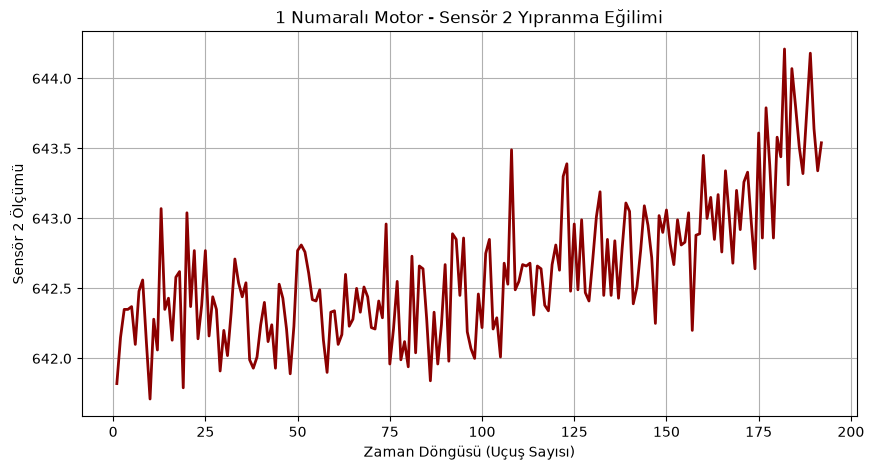

In [ ]:
import matplotlib.pyplot as plt

# Sadece 1 numaralı motorun verilerini izole ediyoruz
motor1_veri = df_train[df_train['Motor_ID'] == 1]

# Grafik boyutunu ayarlıyoruz
plt.figure(figsize=(10, 5))

# X ekseninde Uçuş Sayısı, Y ekseninde Sensor_2 değeri olacak şekilde çizgi grafik oluşturuyoruz
plt.plot(motor1_veri['Zaman_Dongusu'], motor1_veri['Sensor_2'], color='darkred', linewidth=2)

# Grafiğe başlık ve etiketler ekliyoruz
plt.title('1 Numaralı Motor - Sensör 2 Yıpranma Eğilimi')
plt.xlabel('Zaman Döngüsü (Uçuş Sayısı)')
plt.ylabel('Sensör 2 Ölçümü')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Ölçeklendireceğimiz özellikleri seçiyoruz (Motor_ID, Zaman_Dongusu ve RUL hariç tutulur çünkü onlar hedef ve kimliktir)
ozellik_sutunlari = df_train.columns.drop(['Motor_ID', 'Zaman_Dongusu', 'RUL'])

# Tüm değerleri 0 ile 1 arasına sıkıştıracak matematiksel aracı (MinMaxScaler) başlatıyoruz
scaler = MinMaxScaler()

# Verilerimizi ölçeklendirip tabloyu güncelliyoruz
df_train[ozellik_sutunlari] = scaler.fit_transform(df_train[ozellik_sutunlari])

# Ölçeklenmiş yeni tablomuzu ekrana yazdırıyoruz
df_train.head()

,Motor_ID,Zaman_Dongusu,Op_Ayar_1,Op_Ayar_2,Sensor_2,Sensor_3,Sensor_4,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_11,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_17,Sensor_20,Sensor_21,RUL
0,1,1,0.459770,0.166667,0.183735,0.406802,0.309757,1.0,0.726248,0.242424,0.109755,0.369048,0.633262,0.205882,0.199608,0.363986,0.333333,0.713178,0.724662,191
1,1,2,0.609195,0.250000,0.283133,0.453019,0.352633,1.0,0.628019,0.212121,0.100242,0.380952,0.765458,0.279412,0.162813,0.411312,0.333333,0.666667,0.731014,190
2,1,3,0.252874,0.750000,0.343373,0.369523,0.370527,1.0,0.710145,0.272727,0.140043,0.250000,0.795309,0.220588,0.171793,0.357445,0.166667,0.627907,0.621375,189
3,1,4,0.540230,0.500000,0.343373,0.256159,0.331195,1.0,0.740741,0.318182,0.124518,0.166667,0.889126,0.294118,0.174889,0.166603,0.333333,0.573643,0.662386,188
4,1,5,0.390805,0.333333,0.349398,0.257467,0.404625,1.0,0.668277,0.242424,0.149960,0.255952,0.746269,0.235294,0.174734,0.402078,0.416667,0.589147,0.704502,187


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score

# Yapay zekaya vereceğimiz sensör verilerini (X) ve tahmin etmesini istediğimiz hedefi (y - RUL) ayırıyoruz
X = df_train[ozellik_sutunlari]
y = df_train['RUL']

# XGBoost modelimizi oluşturuyoruz (savunma ve havacılık sanayisinde sıkça kullanılan güçlü bir algoritmadır)
model = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)

# Modeli verilerimizle eğitiyoruz ("Sensör verilerine bakarak RUL değerini tahmin etmeyi öğren" diyoruz)
model.fit(X, y)

# Eğittiğimiz modele aynı verileri tekrar verip tahmin yapmasını istiyoruz
tahminler = model.predict(X)

# Modelin tahminlerinin gerçek değerlerle ne kadar örtüştüğünü (R2 Skoru) ölçüyoruz
basari_orani = r2_score(y, tahminler)
print(f"Modelin Öğrenme Başarısı (R2 Skoru): %{basari_orani * 100:.2f}")

NameError: name 'ozellik_sutunlari' is not defined

In [ ]:
import joblib

# Eğittiğimiz XGBoost modelini kaydediyoruz
joblib.dump(model, 'xgboost_rul_modeli.joblib')

# Sensör verilerini ölçeklendiren scaler'ı kaydediyoruz
joblib.dump(scaler, 'veri_olceklendirici.joblib')

# Modeli eğitirken kullandığımız sütun isimlerini kaydediyoruz (arayüzün hangi sütunları beklediğini bilmesi için)
joblib.dump(ozellik_sutunlari, 'ozellik_sutunlari.joblib')

print("Model ve gerekli araçlar proje klasörüne başarıyla kaydedildi!")

NameError: name 'model' is not defined

In [ ]:
# İçinde sadece tek bir benzersiz değer barındıran (hiç değişmeyen) sütunları tespit ediyoruz
sabit_sutunlar = [col for col in df_train.columns if df_train[col].nunique() == 1]

print("Yapay zekaya faydası olmayan ve silinen sütunlar:", sabit_sutunlar)

# Bu gereksiz sütunları tablomuzdan kalıcı olarak siliyoruz
df_train = df_train.drop(columns=sabit_sutunlar)

# Kalan sütunlarımızın yeni halini ekranda gösteriyoruz
df_train.head()


Yapay zekaya faydası olmayan ve silinen sütunlar: ['Op_Ayar_3', 'Sensor_1', 'Sensor_5', 'Sensor_10', 'Sensor_16', 'Sensor_18', 'Sensor_19']


,Motor_ID,Zaman_Dongusu,Op_Ayar_1,Op_Ayar_2,Sensor_2,Sensor_3,Sensor_4,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_11,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_17,Sensor_20,Sensor_21,RUL
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187


In [5]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor
import joblib

# 1. Veriyi okuyoruz
df_train = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None)

# 2. Sütun isimlerini veriyoruz
sutun_isimleri = ['Motor_ID', 'Zaman_Dongusu', 'Op_Ayar_1', 'Op_Ayar_2', 'Op_Ayar_3'] + [f'Sensor_{i}' for i in range(1, 22)]
df_train.columns = sutun_isimleri

# 3. RUL (Kalan Ömür) hesaplıyoruz
max_dongu = df_train.groupby('Motor_ID')['Zaman_Dongusu'].max()
df_train['RUL'] = df_train['Motor_ID'].map(max_dongu) - df_train['Zaman_Dongusu']

# 4. Gereksiz (sabit) sütunları siliyoruz
sabit_sutunlar = [col for col in df_train.columns if df_train[col].nunique() == 1]
df_train = df_train.drop(columns=sabit_sutunlar)

# 5. Özellikleri seçip ölçeklendiriyoruz (Scaler)
ozellik_sutunlari = df_train.columns.drop(['Motor_ID', 'Zaman_Dongusu', 'RUL'])
scaler = MinMaxScaler()
df_train[ozellik_sutunlari] = scaler.fit_transform(df_train[ozellik_sutunlari])

# 6. Modeli eğitiyoruz
X = df_train[ozellik_sutunlari]
y = df_train['RUL']
model = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)
model.fit(X, y)

# 7. Modelimizi ve diğer araçları kaydediyoruz (Pickle/Joblib)
joblib.dump(model, 'xgboost_rul_modeli.joblib')
joblib.dump(scaler, 'veri_olceklendirici.joblib')
joblib.dump(ozellik_sutunlari, 'ozellik_sutunlari.joblib')

print("Tüm işlemler sıfırdan yapıldı ve model başarıyla kaydedildi!")

Tüm işlemler sıfırdan yapıldı ve model başarıyla kaydedildi!
